# 01 · Exploration: does the churn label make sense?

One row per player, built by `sql/01_player_features.sql` from Google's public *Flood It!* Firebase export.

- **churned = 1**: the player shows no activity after their first 24 hours.
- Players who left within 10 minutes (bounces) are excluded.
- Players first seen in the last 48 hours of the export are excluded: they had no time to come back, so their label would be wrong (*right-censoring*).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np

from churn.data import PARQUET_PATH, load_players

df = load_players()
print(f"{len(df):,} players, churn rate {df.churned.mean():.1%}")

8,984 players, churn rate 22.3%


## Churn rate by platform and top countries
DuckDB queries the Parquet file directly with SQL, no database server needed.

In [2]:
duckdb.sql(f"""
    SELECT operating_system, count(*) AS players, round(avg(churned), 3) AS churn_rate
    FROM '{PARQUET_PATH}' GROUP BY ALL ORDER BY players DESC
""").df()

,operating_system,players,churn_rate
0,IOS,4596,0.218
1,ANDROID,4388,0.227


In [3]:
duckdb.sql(f"""
    SELECT country, count(*) AS players, round(avg(churned), 3) AS churn_rate
    FROM '{PARQUET_PATH}' GROUP BY ALL HAVING players >= 200 ORDER BY players DESC
""").df()

,country,players,churn_rate
0,United States,4854,0.196
1,India,631,0.361
2,Japan,491,0.226
3,Canada,391,0.210
4,Australia,342,0.199
5,United Kingdom,331,0.181


## First-day behaviour: churners vs. players who stayed
Medians, because these counts are very skewed: a few players do hundreds of levels.

In [4]:
behaviour = ["sessions", "engagement_seconds", "screen_views", "levels_started",
             "levels_completed", "levels_failed", "scores_posted"]
df.groupby("churned")[behaviour].median().T.rename(columns={0: "stayed", 1: "churned"})

churned,stayed,churned
sessions,1.000,1.0000
engagement_seconds,182.933,533.6025
screen_views,11.000,27.0000
levels_started,3.000,8.0000
levels_completed,1.000,2.0000
levels_failed,0.000,1.0000
scores_posted,1.000,2.0000


## Churn rate by first-day engagement
Players are split into 10 equal groups (deciles) by engagement time.

,churn_rate,median_seconds
engagement_decile,,
1,0.059,0.000
2,0.120,4.130
3,0.201,55.977
4,0.165,110.892
5,0.165,180.698
6,0.194,287.825
7,0.279,461.036
8,0.418,680.419
9,0.368,1127.046


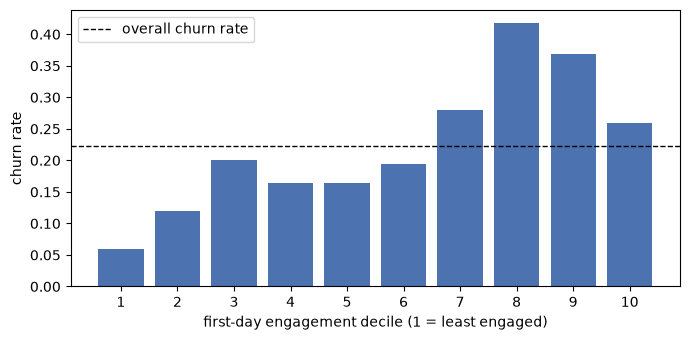

In [5]:
df["engagement_decile"] = (df.engagement_seconds.rank(method="first") * 10 // (len(df) + 1)).astype(int) + 1
by_decile = df.groupby("engagement_decile").agg(churn_rate=("churned", "mean"),
                                                 median_seconds=("engagement_seconds", "median"))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(by_decile.index, by_decile.churn_rate, color="#4C72B0")
ax.axhline(df.churned.mean(), color="k", ls="--", lw=1, label="overall churn rate")
ax.set_xlabel("first-day engagement decile (1 = least engaged)")
ax.set_ylabel("churn rate")
ax.set_xticks(by_decile.index)
ax.legend()
fig.tight_layout()
fig.savefig("../reports/churn_by_engagement.png", dpi=120)
by_decile.round(3)

## What this tells us

- Churn is **not** simply "low engagement". It follows an **inverted U**: the least engaged players churn least (about 6%), churn peaks around 10 to 20 minutes of first-day play (about 40%), and the heaviest players churn less again (about 26%).
- The middle of the curve looks like **"binge, then quit"**: in a casual puzzle game, some players play one long sitting and never return. The very heavy players are probably the ones who got hooked.
- The near-zero-engagement group churning so little is suspicious: many of them are likely existing players whose first event in the export was a short check-in (see the limitation below), and they keep coming back.
- **Limitation:** the export starts on 12 June 2018, so most players were already playing before it began (only a few hundred are fresh installs with a `first_open` event). "First day" here means *first day seen in the export*, not the install day. The model learns "who stops after the first day we observe", which is still useful but should be stated.

Because the relationship is a curve, not a straight line, a tree-based model should beat a linear one. Notebook 02 checks that.